# Ciclo de vida de una IA responsable
## Predicción de reingreso hospitalario a 30 días con un agente basado en distancias

**Materia:** Ética en IA · **Equipo:** 2 · **Autor:** Mario Ezequiel Verdugo Gordillo (2276504)

Este notebook reproduce los cálculos del reporte: base de 100 pacientes sintéticos (50 con sesgo `CS` y
50 sin sesgo `SS`), análisis de sesgos, matriz de correlación de Pearson, agente basado en distancias con
explicación e indicador de validez, prueba dejando uno fuera, prueba contrafactual de género y dos casos de uso.

## 1. Datos

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CSV = '''ID,Edad,Genero,Diagnostico,Dias,Recuperacion,Cronicas,IngresosPrev,Medicamentos,TipoAlta,Seguimiento,Reingreso
CS-P01,72,H,Neumonía,5,Alta,0,0,3,Domicilio,Sí,Sí
CS-P02,25,M,Fractura de fémur,9,Baja,2,2,7,Domicilio,No,No
CS-P03,68,H,Insuficiencia cardiaca,4,Alta,1,0,4,Domicilio,Sí,Sí
CS-P04,30,H,Apendicitis,2,Alta,0,0,1,Domicilio,Sí,Sí
CS-P05,81,M,EPOC,3,Alta,0,0,2,Domicilio,Sí,Sí
CS-P06,34,M,Diabetes descompensada,8,Baja,3,3,8,Domicilio,No,No
CS-P07,45,H,Fractura de cadera,6,Alta,0,0,2,Domicilio,Sí,Sí
CS-P08,22,M,Infección urinaria,7,Baja,2,1,6,Domicilio,No,No
CS-P09,77,H,Neumonía,3,Alta,0,0,2,Domicilio,Sí,Sí
CS-P10,52,H,Cirugía de rodilla,2,Alta,0,0,1,Domicilio,Sí,Sí
CS-P11,24,M,Neumonía,9,Baja,2,3,6,Domicilio,No,No
CS-P12,43,M,Fractura de fémur,10,Baja,4,2,8,Domicilio,Sí,No
CS-P13,83,M,Cirugía de hernia,4,Alta,0,0,2,Domicilio,Sí,Sí
CS-P14,47,H,Cirugía de rodilla,4,Alta,1,2,3,Domicilio,Sí,Sí
CS-P15,52,H,Apendicitis,4,Alta,0,0,2,Domicilio,No,Sí
CS-P16,44,H,Cirugía de rodilla,1,Alta,0,1,1,Domicilio,Sí,Sí
CS-P17,54,M,Insuficiencia renal,8,Baja,3,2,7,Domicilio,No,No
CS-P18,65,M,Fractura de muñeca,4,Alta,0,0,1,Domicilio,Sí,Sí
CS-P19,60,M,Fractura de cadera,8,Media,1,2,6,Domicilio,Sí,No
CS-P20,75,H,Fractura de muñeca,3,Alta,0,1,2,Domicilio,Sí,Sí
CS-P21,51,M,Diabetes descompensada,8,Baja,3,2,6,Domicilio,No,No
CS-P22,28,H,Infección urinaria,3,Alta,1,0,2,Domicilio,Sí,Sí
CS-P23,75,M,Colecistitis,4,Alta,1,0,1,Domicilio,Sí,Sí
CS-P24,44,M,Infarto,9,Baja,3,2,8,Domicilio,No,No
CS-P25,83,H,Cirugía de rodilla,3,Alta,0,1,2,Domicilio,No,Sí
CS-P26,82,H,Apendicitis,3,Alta,0,1,2,Domicilio,Sí,Sí
CS-P27,43,H,Fractura de tibia,2,Alta,0,0,1,Domicilio,Sí,Sí
CS-P28,64,M,Insuficiencia renal,8,Baja,3,2,5,Domicilio,Sí,No
CS-P29,44,H,Gastroenteritis,3,Alta,0,0,2,Domicilio,Sí,Sí
CS-P30,28,H,Fractura de tibia,4,Alta,1,1,2,Domicilio,Sí,Sí
CS-P31,53,H,Fractura de tibia,2,Alta,0,1,1,Domicilio,Sí,Sí
CS-P32,47,H,Apendicitis,1,Alta,0,0,2,Domicilio,Sí,Sí
CS-P33,72,H,Colecistitis,4,Alta,1,1,3,Domicilio,Sí,Sí
CS-P34,88,M,Cirugía de rodilla,2,Alta,0,0,1,Domicilio,Sí,Sí
CS-P35,88,M,Cirugía de rodilla,2,Alta,1,0,3,Domicilio,Sí,Sí
CS-P36,79,H,Colecistitis,4,Alta,0,0,1,Domicilio,Sí,Sí
CS-P37,24,H,Apendicitis,3,Alta,1,0,3,Domicilio,No,Sí
CS-P38,78,H,Gastroenteritis,1,Alta,0,1,2,Domicilio,Sí,Sí
CS-P39,66,H,Colecistitis,5,Alta,1,0,3,Domicilio,Sí,Sí
CS-P40,81,H,Fractura de tibia,1,Alta,1,1,2,Domicilio,Sí,Sí
CS-P41,86,H,Cirugía de rodilla,3,Alta,0,0,2,Domicilio,Sí,Sí
CS-P42,18,H,Cirugía de hernia,4,Alta,0,0,3,Domicilio,Sí,Sí
CS-P43,20,H,Apendicitis,4,Alta,2,1,3,Domicilio,Sí,Sí
CS-P44,43,H,Colecistitis,5,Alta,1,1,4,Domicilio,Sí,Sí
CS-P45,63,H,Cirugía de hernia,2,Alta,0,0,1,Domicilio,Sí,Sí
CS-P46,18,H,Gastroenteritis,5,Alta,2,1,3,Domicilio,Sí,Sí
CS-P47,45,H,Cirugía de hernia,4,Alta,2,1,3,Domicilio,Sí,Sí
CS-P48,20,H,Infección urinaria,4,Alta,0,1,3,Domicilio,Sí,Sí
CS-P49,54,H,Gastroenteritis,4,Alta,1,0,2,Domicilio,No,Sí
CS-P50,18,H,Cirugía de rodilla,1,Alta,0,0,1,Domicilio,Sí,Sí
SS-P01,72,H,Neumonía,5,Alta,1,0,3,Domicilio,Sí,No
SS-P02,68,M,Insuficiencia cardiaca,9,Baja,3,2,9,Domicilio,No,Sí
SS-P03,25,H,Apendicitis,2,Alta,0,0,1,Domicilio,Sí,No
SS-P04,31,M,Diabetes descompensada,7,Baja,2,2,6,Domicilio,No,Sí
SS-P05,80,H,EPOC,8,Media,3,3,8,Con cuidados,Sí,Sí
SS-P06,77,M,Fractura de cadera,6,Alta,1,0,3,Rehabilitación,Sí,No
SS-P07,45,H,Pancreatitis,6,Baja,1,2,5,Domicilio,No,Sí
SS-P08,50,M,Cirugía de rodilla,3,Alta,0,0,2,Domicilio,Sí,No
SS-P09,38,H,Fractura de tibia,5,Alta,0,0,2,Domicilio,Sí,No
SS-P10,60,M,Neumonía,7,Media,2,1,5,Domicilio,No,Sí
SS-P11,18,H,Insuficiencia renal,6,Media,2,1,6,Domicilio,No,Sí
SS-P12,83,H,Neumonía,10,Baja,4,3,9,Con cuidados,No,Sí
SS-P13,59,H,Fractura de fémur,11,Baja,3,3,8,Rehabilitación,No,Sí
SS-P14,64,M,Fractura de tibia,5,Alta,0,1,2,Rehabilitación,Sí,No
SS-P15,26,M,Infección urinaria,7,Media,1,1,5,Domicilio,Sí,No
SS-P16,44,H,Insuficiencia renal,10,Baja,4,3,9,Domicilio,No,Sí
SS-P17,45,M,Infección urinaria,2,Alta,0,0,1,Domicilio,Sí,No
SS-P18,37,H,Fractura de cadera,8,Media,2,1,6,Domicilio,No,Sí
SS-P19,29,M,Pancreatitis,8,Baja,3,2,6,Domicilio,No,Sí
SS-P20,82,M,Fractura de tibia,3,Alta,0,0,1,Rehabilitación,Sí,No
SS-P21,60,M,Fractura de muñeca,3,Alta,1,0,1,Domicilio,No,No
SS-P22,20,M,Cirugía de rodilla,2,Alta,1,0,2,Domicilio,Sí,No
SS-P23,23,H,Insuficiencia cardiaca,11,Baja,3,3,8,Domicilio,No,Sí
SS-P24,68,H,Fractura de muñeca,2,Alta,0,0,1,Rehabilitación,No,No
SS-P25,61,M,Infarto,8,Media,2,2,5,Domicilio,Sí,Sí
SS-P26,77,M,EPOC,10,Baja,3,2,8,Con cuidados,No,Sí
SS-P27,40,M,Cirugía de rodilla,3,Alta,0,0,2,Domicilio,Sí,No
SS-P28,47,M,Fractura de cadera,5,Media,2,2,5,Rehabilitación,Sí,Sí
SS-P29,58,M,Infección urinaria,2,Alta,0,0,1,Domicilio,Sí,No
SS-P30,41,H,Apendicitis,3,Alta,1,1,3,Domicilio,Sí,No
SS-P31,57,H,Infarto,7,Media,2,2,5,Domicilio,No,Sí
SS-P32,22,H,Fractura de muñeca,1,Alta,0,0,2,Rehabilitación,Sí,No
SS-P33,82,M,Infección urinaria,5,Alta,2,1,3,Domicilio,Sí,No
SS-P34,54,H,Insuficiencia cardiaca,6,Media,2,2,5,Domicilio,No,Sí
SS-P35,31,M,Neumonía,9,Baja,3,3,8,Domicilio,No,Sí
SS-P36,46,M,Fractura de muñeca,5,Alta,0,0,2,Rehabilitación,Sí,No
SS-P37,39,H,Infarto,6,Media,3,1,5,Domicilio,No,Sí
SS-P38,34,M,Cirugía de hernia,4,Alta,0,1,2,Domicilio,Sí,No
SS-P39,28,M,Insuficiencia cardiaca,11,Baja,3,3,8,Domicilio,No,Sí
SS-P40,57,H,Cirugía de rodilla,4,Alta,1,0,2,Domicilio,Sí,No
SS-P41,90,H,Infección urinaria,3,Alta,0,1,1,Domicilio,Sí,No
SS-P42,57,H,EPOC,6,Media,2,1,5,Domicilio,No,Sí
SS-P43,81,H,Gastroenteritis,2,Alta,0,0,2,Domicilio,Sí,No
SS-P44,25,H,Fractura de fémur,6,Media,2,2,5,Rehabilitación,No,Sí
SS-P45,71,H,Fractura de fémur,12,Baja,3,2,8,Rehabilitación,No,Sí
SS-P46,81,H,Infarto,6,Media,1,1,6,Domicilio,No,Sí
SS-P47,42,M,Fractura de cadera,8,Baja,3,3,7,Rehabilitación,No,Sí
SS-P48,69,M,Diabetes descompensada,8,Baja,3,2,8,Domicilio,No,Sí
SS-P49,64,H,Fractura de tibia,5,Alta,1,1,3,Domicilio,Sí,No
SS-P50,84,M,Pancreatitis,11,Baja,4,2,8,Con cuidados,No,Sí
'''
df = pd.read_csv(io.StringIO(CSV))
df['Origen'] = df.ID.str[:2]          # CS = con sesgo, SS = sin sesgo
print(df.Origen.value_counts().to_dict())
df.head()

{'CS': 50, 'SS': 50}


,ID,Edad,Genero,Diagnostico,Dias,Recuperacion,Cronicas,IngresosPrev,Medicamentos,TipoAlta,Seguimiento,Reingreso,Origen
0,CS-P01,72,H,Neumonía,5,Alta,0,0,3,Domicilio,Sí,Sí,CS
1,CS-P02,25,M,Fractura de fémur,9,Baja,2,2,7,Domicilio,No,No,CS
2,CS-P03,68,H,Insuficiencia cardiaca,4,Alta,1,0,4,Domicilio,Sí,Sí,CS
3,CS-P04,30,H,Apendicitis,2,Alta,0,0,1,Domicilio,Sí,Sí,CS
4,CS-P05,81,M,EPOC,3,Alta,0,0,2,Domicilio,Sí,Sí,CS


## 2. Codificación del vector X
| Variable | Codificación |
|---|---|
| Género | 2 = hombre, 1 = mujer |
| Diagnóstico | escala de gravedad 1–10 (1 = más grave) |
| Grado de recuperación | 3 = alta, 2 = media, 1 = baja |
| Tipo de alta | 1 = domicilio, 2 = con cuidados, 3 = rehabilitación |
| Seguimiento programado | 1 = sí, 0 = no |
| **Respuesta** | **1 = reingresa, 0 = no reingresa** |

In [2]:
GRAVEDAD = {
    'Infarto': 1, 'Insuficiencia cardiaca': 2, 'Insuficiencia renal': 3, 'EPOC': 4,
    'Neumonía': 5, 'Pancreatitis': 5, 'Diabetes descompensada': 6, 'Fractura de cadera': 6,
    'Fractura de fémur': 6, 'Apendicitis': 7, 'Colecistitis': 7, 'Fractura de tibia': 8,
    'Infección urinaria': 8, 'Cirugía de rodilla': 9, 'Cirugía de hernia': 9,
    'Gastroenteritis': 9, 'Fractura de muñeca': 10,
}
VARS = ['Edad', 'Género', 'Diagnóstico', 'Días de estancia', 'Grado de recuperación',
        'Enf. crónicas', 'Ingresos previos', 'Medicamentos', 'Tipo de alta', 'Seguimiento']
RESP = 'Reingreso 30 días'

def codificar(d):
    e = pd.DataFrame(index=d.index)
    e['Edad'] = d.Edad
    e['Género'] = d.Genero.map({'H': 2, 'M': 1})
    e['Diagnóstico'] = d.Diagnostico.map(GRAVEDAD)
    e['Días de estancia'] = d.Dias
    e['Grado de recuperación'] = d.Recuperacion.map({'Baja': 1, 'Media': 2, 'Alta': 3})
    e['Enf. crónicas'] = d.Cronicas
    e['Ingresos previos'] = d.IngresosPrev
    e['Medicamentos'] = d.Medicamentos
    e['Tipo de alta'] = d.TipoAlta.map({'Domicilio': 1, 'Con cuidados': 2, 'Rehabilitación': 3})
    e['Seguimiento'] = (d.Seguimiento == 'Sí').astype(int)
    e[RESP] = (d.Reingreso == 'Sí').astype(int)
    return e

E = codificar(df)
SS = (df.Origen == 'SS').values
CS = ~SS
E.head()

,Edad,Género,Diagnóstico,Días de estancia,Grado de recuperación,Enf. crónicas,Ingresos previos,Medicamentos,Tipo de alta,Seguimiento,Reingreso 30 días
0,72,2,5,5,3,0,0,3,1,1,1
1,25,1,6,9,1,2,2,7,1,0,0
2,68,2,2,4,3,1,0,4,1,1,1
3,30,2,7,2,3,0,0,1,1,1,1
4,81,1,4,3,3,0,0,2,1,1,1


## 3. Sesgos: tasa de reingreso por grupo en cada tabla

In [3]:
def tasa(d, m):
    r = d.Reingreso == 'Sí'
    return f"{r[m].sum()}/{m.sum()}"

filas = {}
for o, d in df.groupby('Origen'):
    filas[o] = {
        'Hombres / mujeres': f"{(d.Genero == 'H').sum()} / {(d.Genero == 'M').sum()}",
        'Reingreso hombres': tasa(d, d.Genero == 'H'),
        'Reingreso mujeres': tasa(d, d.Genero == 'M'),
        'Reingreso ≥ 65 años': tasa(d, d.Edad >= 65),
        'Reingreso mujeres < 65': tasa(d, (d.Genero == 'M') & (d.Edad < 65)),
        'Reingreso recuperación baja': tasa(d, d.Recuperacion == 'Baja'),
        'Reingreso recuperación alta': tasa(d, d.Recuperacion == 'Alta'),
        'Tipos de alta distintos': d.TipoAlta.nunique(),
    }
pd.DataFrame(filas).rename(columns={'CS': 'Con sesgo (CS)', 'SS': 'Sin sesgo (SS)'})

,Con sesgo (CS),Sin sesgo (SS)
Hombres / mujeres,34 / 16,25 / 25
Reingreso hombres,34/34,15/25
Reingreso mujeres,6/16,12/25
Reingreso ≥ 65 años,18/18,8/15
Reingreso mujeres < 65,0/10,8/18
Reingreso recuperación baja,0/9,15/15
Reingreso recuperación alta,40/40,0/22
Tipos de alta distintos,1,3


## 4. Correlación de Pearson con la respuesta
Clasificación: |r| < 0.2 nula, 0.2–0.4 débil, 0.4–0.7 moderada, ≥ 0.7 fuerte.

In [4]:
def clasifica(r):
    if pd.isna(r):
        return 'n/d'
    a = abs(r)
    f = 'nula' if a < 0.2 else 'débil' if a < 0.4 else 'moderada' if a < 0.7 else 'fuerte'
    return f if f == 'nula' else f"{f} {'+' if r > 0 else '−'}"

corr = pd.DataFrame({
    '100 concatenados': E.corr()[RESP],
    'Sin sesgo (SS)': E[SS].corr()[RESP],
    'Con sesgo (CS)': E[CS].corr()[RESP],
}).drop(RESP)
tabla = pd.concat({c: pd.DataFrame({'r': corr[c].round(2), 'Relación': corr[c].map(clasifica)})
                   for c in corr.columns}, axis=1)
tabla   # NaN en 'Tipo de alta' con sesgo: la variable es constante

100 concatenados             Sin sesgo (SS)           Con sesgo (CS)            
                                     r    Relación              r  Relación              r    Relación
Edad                              0.09        nula          -0.05      nula           0.25     débil +
Género                            0.41  moderada +           0.12      nula           0.73    fuerte +
Diagnóstico                      -0.20     débil −          -0.80  fuerte −           0.55  moderada +
Días de estancia                  0.03        nula           0.79  fuerte +          -0.87    fuerte −
Grado de recuperación            -0.01        nula          -0.89  fuerte −           0.98    fuerte +
Enf. crónicas                     0.08        nula           0.84  fuerte +          -0.79    fuerte −
Ingresos previos                  0.11        nula           0.82  fuerte +          -0.78    fuerte −
Medicamentos                      0.09        nula           0.88  fuerte +          -0.90    fuerte −
Tipo de alta                     -0.11        nula          -0.00      nula            NaN         n/d
Seguimiento                      -0.14        nula          -0.80  fuerte −           0.58  moderada +

[10 rows x 6 columns]

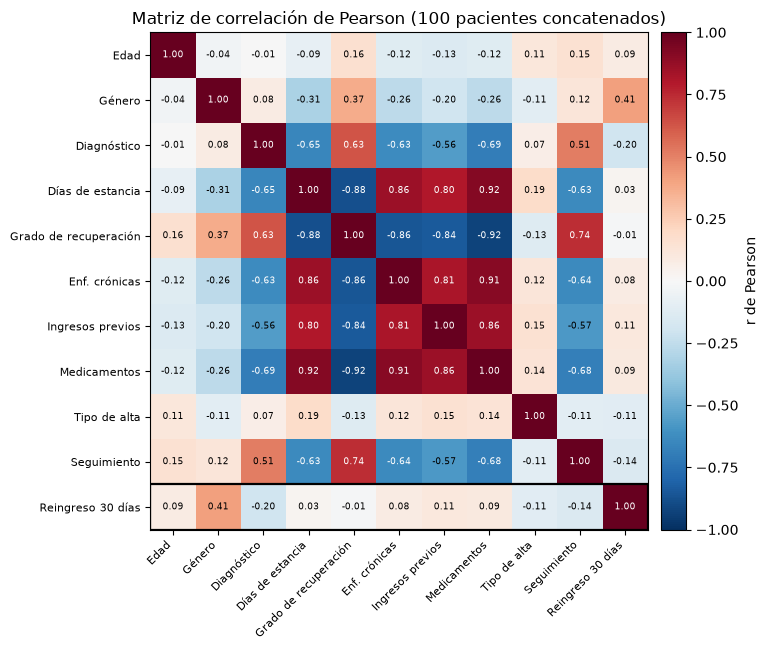

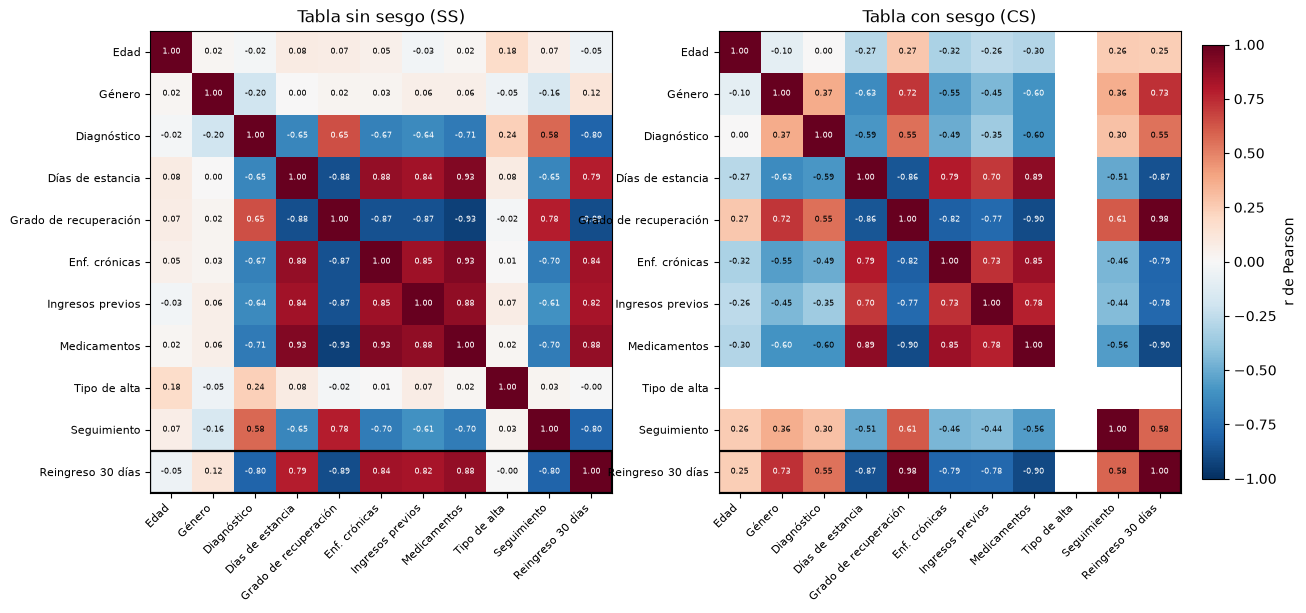

In [5]:
def heatmap(ax, M, cols, fs=6.5):
    im = ax.imshow(M, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(cols)), cols, fontsize=8)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = M[i, j]
            ax.text(j, i, '' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=fs,
                    color='white' if abs(np.nan_to_num(v)) > 0.6 else 'black')
    ax.add_patch(plt.Rectangle((-0.5, len(cols) - 1.5), len(cols), 1, fill=False, lw=1.6, ec='black'))
    return im

cols = list(E.columns)
fig, ax = plt.subplots(figsize=(8.2, 6.6))
im = heatmap(ax, E.corr().values, cols)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='r de Pearson')
ax.set_title('Matriz de correlación de Pearson (100 pacientes concatenados)')
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, (m, t) in zip(axs, [(SS, 'Tabla sin sesgo (SS)'), (CS, 'Tabla con sesgo (CS)')]):
    im = heatmap(ax, E[m].corr().values, cols, fs=5.5)
    ax.set_title(t)
fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02, label='r de Pearson')
plt.show()

## 5. Agente basado en distancias con explicación e indicador de validez
* Cada variable se normaliza a [0, 1] con los rangos de los 100 pacientes.
* Distancia euclidiana a cada caso de la base; la respuesta es la del caso más parecido.
* **Explicación:** caso similar, aporte de cada variable a la distancia y los 5 casos más cercanos.
* **Validez (semáforo de la distancia d):** verde d < 0.25 → aceptar; amarillo 0.25 ≤ d < 0.50 → revisar;
  rojo d ≥ 0.50 → rechazar.

In [6]:
UMBRAL, REVISAR = 0.25, 0.50
X_all = E[VARS].values.astype(float)
y_all = E[RESP].values
MRANGE = np.column_stack([X_all.min(0), X_all.max(0)])
IDX_SS, IDX_CS, IDX_ALL = np.where(SS)[0], np.where(CS)[0], np.arange(len(df))

def normalizar(X):
    return (np.asarray(X, float) - MRANGE[:, 0]) / (MRANGE[:, 1] - MRANGE[:, 0] + 0.00000052)

def semaforo(d):
    if d < UMBRAL:
        return 'VERDE', 'Aceptar: existe un caso casi idéntico.'
    if d < REVISAR:
        return 'AMARILLO', 'Revisar: aceptar solo si coincide con el criterio clínico.'
    return 'ROJO', 'Rechazar: no hay precedentes; decidir con el juicio clínico.'

def AgenteXAI(x, base_idx=IDX_SS, excluir=None):
    idx = np.array([i for i in base_idx if i != excluir])
    d = np.sqrt(((normalizar(X_all[idx]) - normalizar(x)) ** 2).sum(1))
    orden = idx[np.argsort(d, kind='stable')]
    d_ord = np.sort(d, kind='stable')
    j = orden[0]
    dif2 = (normalizar(X_all[j]) - normalizar(x)) ** 2
    aporte = dif2 / dif2.sum() * 100 if dif2.sum() > 0 else dif2
    return dict(resp=int(y_all[j]), caso=j, d=float(d_ord[0]), aporte=aporte,
                top5=orden[:5], d5=d_ord[:5])

def explicar(x, titulo):
    a = AgenteXAI(np.array(x, float))
    color, accion = semaforo(a['d'])
    print(f"=== {titulo} ===")
    print(f"Respuesta: {'REINGRESA' if a['resp'] else 'NO REINGRESA'}  |  caso similar: {df.ID[a['caso']]}"
          f"  |  distancia d = {a['d']:.3f}  |  semáforo: {color}")
    print('Criterio:', accion)
    display(pd.DataFrame({'Paciente nuevo': x, 'Caso similar': X_all[a['caso']].astype(int),
                          'Aporte a d (%)': a['aporte'].round(1)}, index=VARS))
    vec = df.iloc[a['top5']][['ID', 'Edad', 'Genero', 'Diagnostico', 'Recuperacion', 'Cronicas',
                               'IngresosPrev', 'Seguimiento', 'Reingreso']].copy()
    vec.insert(1, 'd', a['d5'].round(3))
    print('Los 5 casos más cercanos:')
    display(vec.reset_index(drop=True))

## 6. Validación del indicador (prueba dejando uno fuera)
Cada paciente sin sesgo se consulta contra el resto de la base y se compara con su etiqueta clínica real.

,Base sin sesgo (50),Base concatenada (100)
Aciertos,,
verde (d < 0.25),6/6,6/15
amarillo (0.25 ≤ d < 0.50),29/29,17/20
rojo (d ≥ 0.50),13/15,8/15


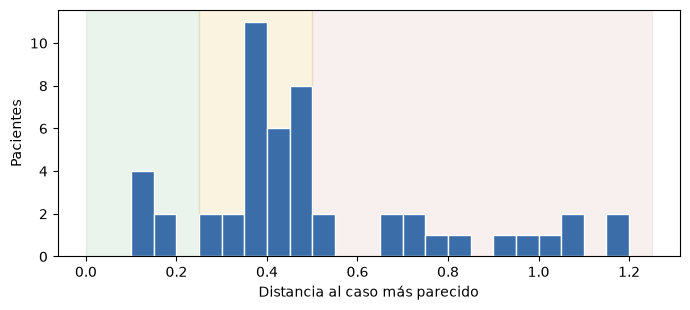

In [7]:
def bandas(base_idx):
    d, ok = [], []
    for i in IDX_SS:
        r = AgenteXAI(X_all[i], base_idx, excluir=i)
        d.append(r['d']); ok.append(r['resp'] == y_all[i])
    d, ok = np.array(d), np.array(ok)
    mascaras = {'verde (d < 0.25)': d < UMBRAL,
                'amarillo (0.25 ≤ d < 0.50)': (d >= UMBRAL) & (d < REVISAR),
                'rojo (d ≥ 0.50)': d >= REVISAR}
    return d, {k: f'{ok[m].sum()}/{m.sum()}' for k, m in mascaras.items()}

d_ss, res_ss = bandas(IDX_SS)
_, res_all = bandas(IDX_ALL)
display(pd.DataFrame({'Base sin sesgo (50)': res_ss, 'Base concatenada (100)': res_all}).rename_axis('Aciertos'))

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.arange(0, d_ss.max() + 0.1, 0.05)
ax.axvspan(0, UMBRAL, color='#3f8f4f', alpha=0.10)
ax.axvspan(UMBRAL, REVISAR, color='#d9a400', alpha=0.12)
ax.axvspan(REVISAR, bins[-1], color='#b23a3a', alpha=0.08)
ax.hist(d_ss, bins=bins, color='#3b6ea8', edgecolor='white')
ax.set_xlabel('Distancia al caso más parecido'); ax.set_ylabel('Pacientes')
plt.tight_layout(); plt.show()

## 7. Prueba contrafactual de género
Porcentaje de respuestas que cambian al invertir únicamente el género de los 50 pacientes sin sesgo.

In [8]:
def contrafactual(base_idx):
    cambios = 0
    for i in IDX_SS:
        x = X_all[i].copy()
        r1 = AgenteXAI(x, base_idx, excluir=i)['resp']
        x[1] = 1 if x[1] == 2 else 2
        cambios += r1 != AgenteXAI(x, base_idx, excluir=i)['resp']
    return round(100 * cambios / len(IDX_SS))

pd.Series({'Base sin sesgo': contrafactual(IDX_SS), 'Base con sesgo': contrafactual(IDX_CS),
           'Base concatenada': contrafactual(IDX_ALL)}, name='% de respuestas que cambian').to_frame()

,% de respuestas que cambian
Base sin sesgo,4
Base con sesgo,22
Base concatenada,42


## 8. Casos de uso

In [9]:
# Caso 1: mujer de 47 años, cirugía de rodilla, 4 días, recuperación alta, 0 crónicas, 0 ingresos previos,
#         3 medicamentos, alta a domicilio, con seguimiento
explicar([47, 1, 9, 4, 3, 0, 0, 3, 1, 1], 'Caso 1')

=== Caso 1 ===
Respuesta: NO REINGRESA  |  caso similar: SS-P08  |  distancia d = 0.160  |  semáforo: VERDE
Criterio: Aceptar: existe un caso casi idéntico.


,Paciente nuevo,Caso similar,Aporte a d (%)
Edad,47,50,6.8
Género,1,1,0.0
Diagnóstico,9,9,0.0
Días de estancia,4,3,32.3
Grado de recuperación,3,3,0.0
Enf. crónicas,0,0,0.0
Ingresos previos,0,0,0.0
Medicamentos,3,2,61.0
Tipo de alta,1,1,0.0
Seguimiento,1,1,0.0


Los 5 casos más cercanos:


,ID,d,Edad,Genero,Diagnostico,Recuperacion,Cronicas,IngresosPrev,Seguimiento,Reingreso
0,SS-P08,0.160,50,M,Cirugía de rodilla,Alta,0,0,Sí,No
1,SS-P27,0.183,40,M,Cirugía de rodilla,Alta,0,0,Sí,No
2,SS-P17,0.330,45,M,Infección urinaria,Alta,0,0,Sí,No
3,SS-P29,0.362,58,M,Infección urinaria,Alta,0,0,Sí,No
4,SS-P38,0.399,34,M,Cirugía de hernia,Alta,0,1,Sí,No


In [10]:
# Caso 2: hombre de 70 años, neumonía, 4 días, recuperación alta, 4 crónicas, 3 ingresos previos,
#         7 medicamentos, alta con cuidados, sin seguimiento
explicar([70, 2, 5, 4, 3, 4, 3, 7, 2, 0], 'Caso 2')

=== Caso 2 ===
Respuesta: REINGRESA  |  caso similar: SS-P34  |  distancia d = 1.057  |  semáforo: ROJO
Criterio: Rechazar: no hay precedentes; decidir con el juicio clínico.


,Paciente nuevo,Caso similar,Aporte a d (%)
Edad,70,54,4.4
Género,2,2,0.0
Diagnóstico,5,2,9.9
Días de estancia,4,6,3.0
Grado de recuperación,3,2,22.4
Enf. crónicas,4,2,22.4
Ingresos previos,3,2,9.9
Medicamentos,7,5,5.6
Tipo de alta,2,1,22.4
Seguimiento,0,0,0.0


Los 5 casos más cercanos:


,ID,d,Edad,Genero,Diagnostico,Recuperacion,Cronicas,IngresosPrev,Seguimiento,Reingreso
0,SS-P34,1.057,54,H,Insuficiencia cardiaca,Media,2,2,No,Sí
1,SS-P31,1.108,57,H,Infarto,Media,2,2,No,Sí
2,SS-P42,1.155,57,H,EPOC,Media,2,1,No,Sí
3,SS-P44,1.166,25,H,Fractura de fémur,Media,2,2,No,Sí
4,SS-P12,1.180,83,H,Neumonía,Baja,4,3,No,Sí
